In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
import sys
import json
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Masuk ke folder utama proyek
PROJECT = "/content/drive/MyDrive/simuteh-2330511058"
os.chdir(PROJECT)

# Membuat folder hasil jika belum tersedia
HASIL = os.path.join(PROJECT, "hasil")
os.makedirs(HASIL, exist_ok=True)

# Memanggil modul dari folder src
sys.path.append(PROJECT)

from src.praproses import praproses, simpan_param
from src.utils_cv import kontras_bercak

print("Folder proyek:", os.getcwd())
print("Folder hasil:", HASIL)
print("Folder hasil tersedia:", os.path.exists(HASIL))

Mounted at /content/drive
Folder proyek: /content/drive/MyDrive/simuteh-2330511058
Folder hasil: /content/drive/MyDrive/simuteh-2330511058/hasil
Folder hasil tersedia: True


In [5]:
from google.colab import drive
drive.mount('/content/drive')

import os
import sys

PROJECT = "/content/drive/MyDrive/simuteh-2330511058"

os.chdir(PROJECT)
sys.path.insert(0, os.path.join(PROJECT, "src"))

print("Folder kerja:", os.getcwd())
print("File utils_cv.py tersedia:", os.path.exists("src/utils_cv.py"))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Folder kerja: /content/drive/MyDrive/simuteh-2330511058
File utils_cv.py tersedia: True


In [2]:
import sys
import importlib.util

path = "/content/drive/MyDrive/simuteh-2330511058/src/utils_tepi.py"

spec = importlib.util.spec_from_file_location("utils_tepi", path)
utils_tepi = importlib.util.module_from_spec(spec)
sys.modules["utils_tepi"] = utils_tepi
spec.loader.exec_module(utils_tepi)

from utils_tepi import (
    tepi_acuan,
    skor_tepi,
    iou,
    mask_daun_awal,
    bercak_awal
)

print("Semua fungsi berhasil diimpor!")

Semua fungsi berhasil diimpor!


In [6]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from utils_cv import baca, tampil
from praproses import praproses

from utils_tepi import (
    tepi_acuan,
    skor_tepi,
    iou,
    mask_daun_awal,
    bercak_awal
)

In [8]:
def muat(nama):
    img = baca(f"data/sintetis/citra/{nama}")
    md = cv2.imread(
        f"data/sintetis/mask_daun/{nama}",
        cv2.IMREAD_GRAYSCALE
    )
    mb = cv2.imread(
        f"data/sintetis/mask_bercak/{nama}",
        cv2.IMREAD_GRAYSCALE
    )

    return img, md, mb

In [10]:
import json

PARAM = json.load(
    open("hasil/param_praproses.json")
)

print(PARAM)

{'lebar': 640, 'gamma': 1.0, 'clahe_clip': 2.0, 'clahe_tile': 8, 'penapis': 'median', 'kernel': 3, 'sigma': 1.0, 'tajam_k': 0.0}


##**Kode 3.1 – Mask Daun Awal dan Bercak Awal**

         citra  IoU daun awal  komponen bercak awal  komponen acuan  \
0  teh_041.png          0.994                   168              11   
1  teh_021.png          0.998                   152               1   
2  teh_011.png          0.995                    47               0   

  IoU bercak awal  
0           0.678  
1           0.116  
2               -  


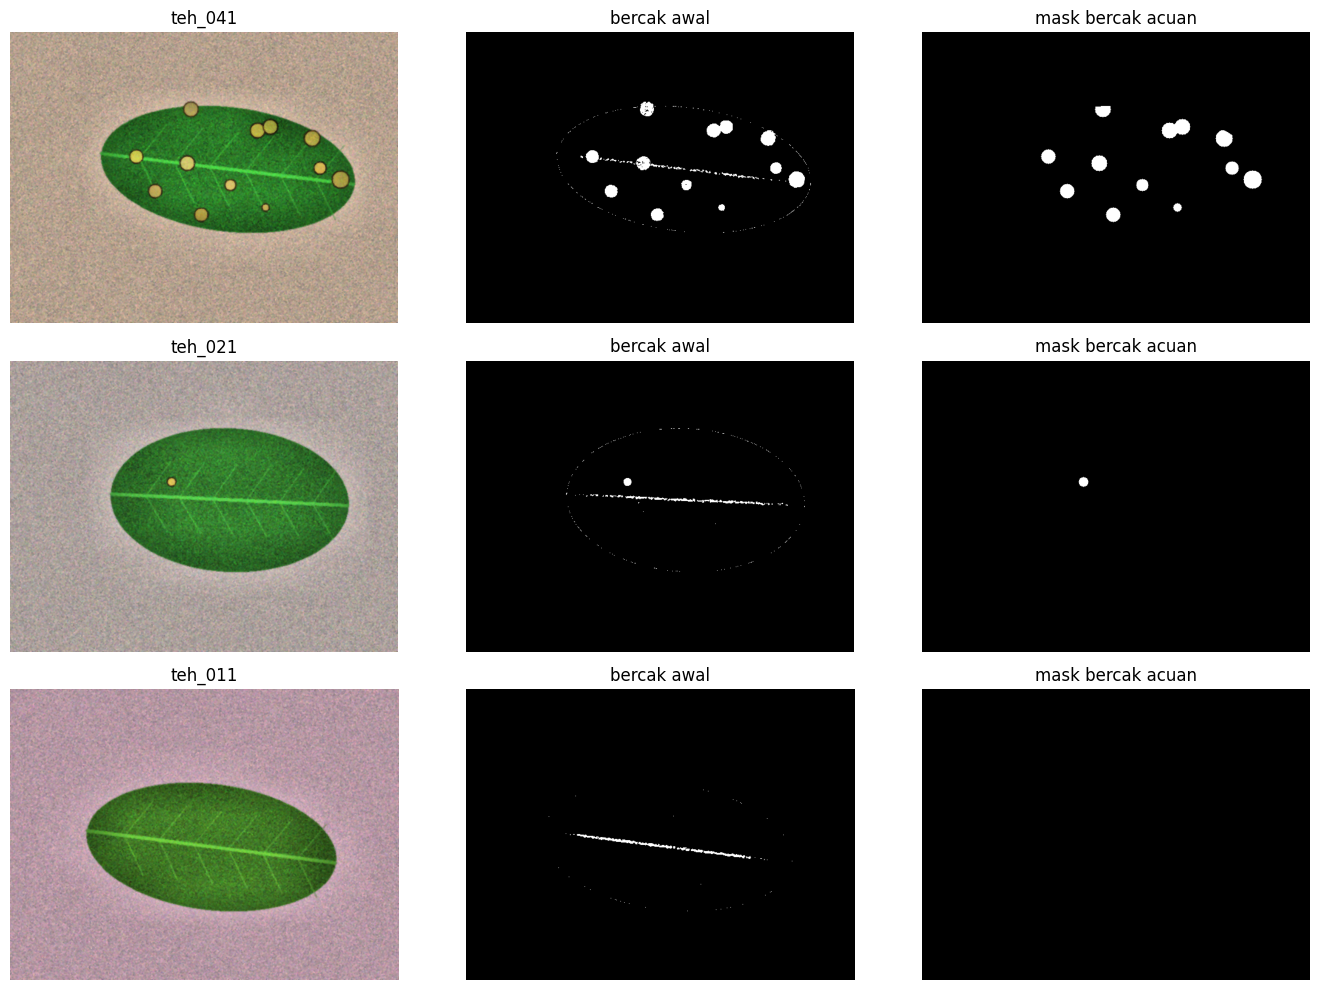

In [11]:
def jumlah_komponen(m, konek=8):
    return cv2.connectedComponents(
        (m > 0).astype(np.uint8),
        connectivity=konek
    )[0] - 1


baris, panel, judul = [], [], []

for nama in [
    "teh_041.png",
    "teh_021.png",
    "teh_011.png"
]:  # berat, ringan, sehat

    img, md, mb = muat(nama)

    pra_ = praproses(img, PARAM)

    m_daun = mask_daun_awal(pra_)

    b0 = bercak_awal(
        pra_,
        m_daun,
        kanal=2,
        k=4.0
    )

    baris.append([
        nama,
        round(iou(m_daun, md), 3),
        jumlah_komponen(b0),
        jumlah_komponen(mb),
        round(iou(b0, mb), 3) if mb.any() else "-"
    ])

    panel += [pra_, b0, mb]

    judul += [
        nama[:7],
        "bercak awal",
        "mask bercak acuan"
    ]


print(
    pd.DataFrame(
        baris,
        columns=[
            "citra",
            "IoU daun awal",
            "komponen bercak awal",
            "komponen acuan",
            "IoU bercak awal"
        ]
    )
)


tampil(
    panel,
    judul,
    baris=3,
    ukuran=(14, 10)
)

##**Kode 3.2 Erosi, dilasi, opening, dan closing**

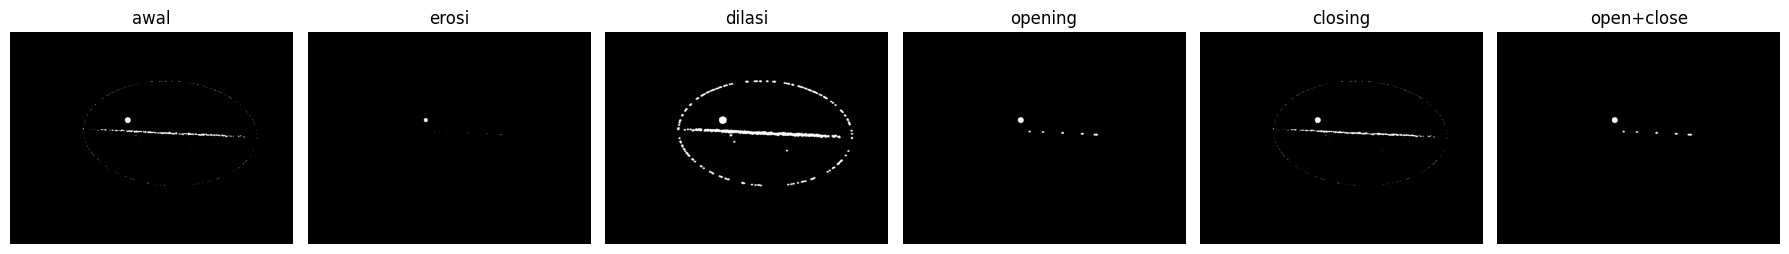

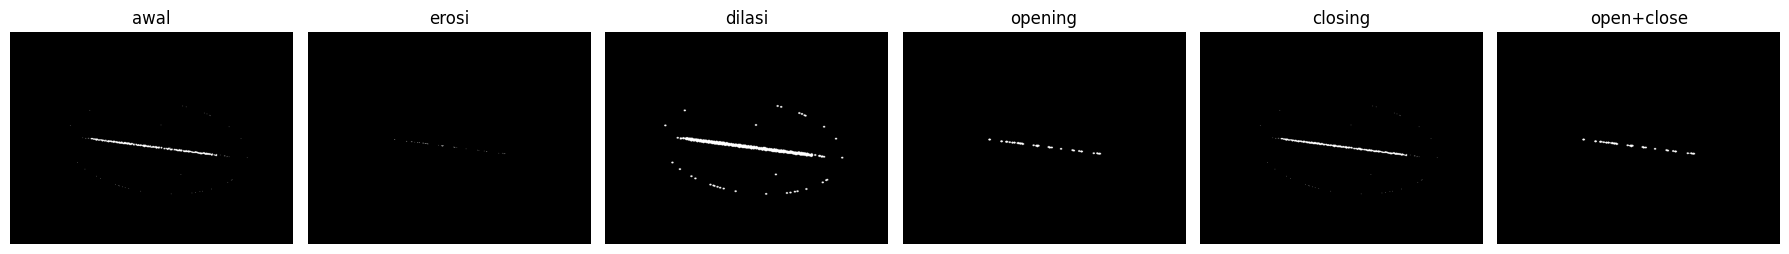

          citra     operasi  komponen  piksel    IoU
0   teh_021.png        awal       152    1141  0.116
1   teh_021.png       erosi         9      76  0.319
2   teh_021.png      dilasi        62    4689  0.042
3   teh_021.png     opening         6     257  0.437
4   teh_021.png     closing       139    1237  0.107
5   teh_021.png  open+close         6     257  0.437
6   teh_011.png        awal        47    1101      -
7   teh_011.png       erosi        22      47      -
8   teh_011.png      dilasi        34    2967      -
9   teh_011.png     opening        14     451      -
10  teh_011.png     closing        41    1159      -
11  teh_011.png  open+close         9     464      -


In [12]:
SE = lambda k, bentuk=cv2.MORPH_ELLIPSE: cv2.getStructuringElement(
    bentuk,
    (k, k)
)


def operasi(b, se):
    return {
        "awal": b,
        "erosi": cv2.erode(b, se),
        "dilasi": cv2.dilate(b, se),
        "opening": cv2.morphologyEx(b, cv2.MORPH_OPEN, se),
        "closing": cv2.morphologyEx(b, cv2.MORPH_CLOSE, se),
        "open+close": cv2.morphologyEx(
            cv2.morphologyEx(b, cv2.MORPH_OPEN, se),
            cv2.MORPH_CLOSE,
            se
        )
    }


baris = []

for nama in [
    "teh_021.png",
    "teh_011.png"
]:
    img, md, mb = muat(nama)

    pra_ = praproses(img, PARAM)

    b0 = bercak_awal(
        pra_,
        mask_daun_awal(pra_)
    )

    hasil = operasi(b0, SE(5))

    for nm, m in hasil.items():
        baris.append([
            nama,
            nm,
            jumlah_komponen(m),
            int((m > 0).sum()),
            round(iou(m, mb), 3) if mb.any() else "-"
        ])

    tampil(
        list(hasil.values()),
        list(hasil.keys()),
        ukuran=(18, 3)
    )

    plt.show()


print(
    pd.DataFrame(
        baris,
        columns=[
            "citra",
            "operasi",
            "komponen",
            "piksel",
            "IoU"
        ]
    )
)

##**Kode 3.3 Eksperimen k, bentuk, dan ukuran SE**

In [15]:
bentuk = {
    "persegi": cv2.MORPH_RECT,
    "elips": cv2.MORPH_ELLIPSE,
    "silang": cv2.MORPH_CROSS
}

baris = []
label = pd.read_csv("data/sintetis/label.csv")

print(label.head())
print("Jumlah data:", len(label))

for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)

    pra_ = praproses(img, PARAM)

    m_daun = mask_daun_awal(pra_)

    n_acuan = jumlah_komponen(mb)

    for k in [3, 4, 6]:
        b0 = bercak_awal(
            pra_,
            m_daun,
            k=k
        )

        for nb, kb in bentuk.items():
            for uk in [3, 5, 7]:
                se = SE(uk, kb)

                m = cv2.morphologyEx(
                    cv2.morphologyEx(
                        b0,
                        cv2.MORPH_OPEN,
                        se
                    ),
                    cv2.MORPH_CLOSE,
                    se
                )

                baris.append([
                    d.kelas,
                    k,
                    nb,
                    uk,
                    abs(jumlah_komponen(m) - n_acuan),
                    iou(m, mb) if mb.any() else np.nan
                ])


eks = pd.DataFrame(
    baris,
    columns=[
        "kelas",
        "k",
        "bentuk",
        "ukuran",
        "galat_jumlah",
        "IoU"
    ]
)


print(
    eks.pivot_table(
        index=["k", "bentuk", "ukuran"],
        columns="kelas",
        values=["galat_jumlah", "IoU"]
    ).round(2)
)


eks.to_csv(
    "hasil/p6_eksperimen_se.csv",
    index=False
)

     nama_file  kelas  kondisi_cahaya  persen_bercak
0  teh_001.png  sehat          normal            0.0
1  teh_002.png  sehat           gelap            0.0
2  teh_003.png  sehat          terang            0.0
3  teh_004.png  sehat  kontras_rendah            0.0
4  teh_005.png  sehat        bayangan            0.0
Jumlah data: 60
                   IoU        galat_jumlah              
kelas            berat ringan        berat ringan  sehat
k bentuk  ukuran                                        
3 elips   3       0.60   0.17        12.85  18.60  22.20
          5       0.62   0.25         4.10   2.60   4.30
          7       0.69   0.41         1.90   3.35   1.40
  persegi 3       0.61   0.20         4.65   6.80   8.45
          5       0.66   0.30         3.30   2.90   3.40
          7       0.67   0.46         0.55   0.50   0.05
  silang  3       0.60   0.17        12.85  18.60  22.20
          5       0.63   0.24         5.95   5.10   7.30
          7       0.70   0.41         3

In [17]:
def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)

    return cv2.Canny(g, lo, hi)

##**Kode 3.4 Gradien morfologi dibandingkan dengan Canny baris**

In [18]:
baris = []

for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)

    pra_ = praproses(img, PARAM)

    m_daun = mask_daun_awal(pra_)

    grad = cv2.morphologyEx(
        m_daun,
        cv2.MORPH_GRADIENT,
        SE(3)
    )  # dilasi - erosi

    canny = tepi_canny(
        cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)
    )

    ad = tepi_acuan(md)

    baris.append([
        d.kondisi_cahaya,
        skor_tepi(grad, ad)[2],
        skor_tepi(canny, ad)[2]
    ])


print(
    pd.DataFrame(
        baris,
        columns=[
            "kondisi",
            "F1 gradien morfologi",
            "F1 Canny"
        ]
    )
    .groupby("kondisi")
    .mean()
    .round(3)
)

                F1 gradien morfologi  F1 Canny
kondisi                                       
bayangan                       0.874     0.705
gelap                          0.972     0.676
kontras_rendah                 0.231     0.900
normal                         0.979     0.689
terang                         0.949     0.692


##**tampilkan elemen SE persegi, elips, dan silang berukuran 3, 5, dan 7**

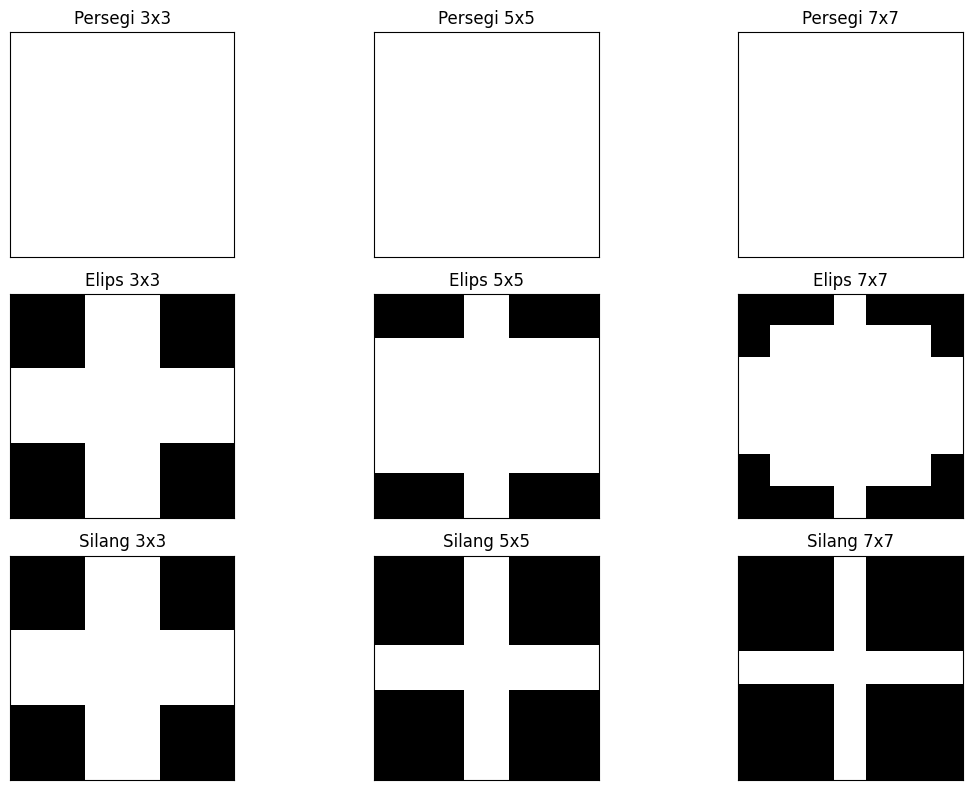

In [19]:
bentuk = {
    "Persegi": cv2.MORPH_RECT,
    "Elips": cv2.MORPH_ELLIPSE,
    "Silang": cv2.MORPH_CROSS
}

ukuran = [3, 5, 7]

plt.figure(figsize=(12, 8))

i = 1

for nama, bentuk_se in bentuk.items():
    for k in ukuran:
        se = cv2.getStructuringElement(
            bentuk_se,
            (k, k)
        )

        plt.subplot(3, 3, i)
        plt.imshow(se, cmap="gray", vmin=0, vmax=1)
        plt.title(f"{nama} {k}x{k}")
        plt.xticks([])
        plt.yticks([])

        i += 1

plt.tight_layout()
plt.show()

##**Kode 4.1 Komponen terhubung dan pengukuran setiap bercak**

konektivitas 4: 11 komponen
konektivitas 8: 11 komponen
    label  luas_px  luas_mm2  keliling_px  kebulatan  rasio_aspek   cx   cy
0       1      388     74.27         78.8       0.79         1.04  298  126
1       2      808    154.66        124.6       0.65         1.95  418  159
2       3      482     92.26         81.0       0.92         1.05  497  174
3       4      356     68.14         68.3       0.96         1.00  208  205
4       5      341     65.27         81.9       0.64         1.10  293  215
5       6      286     54.74         60.3       0.99         1.00  510  224
6       7      570    109.10         87.0       0.95         1.00  545  242
7       8      229     43.83         54.4       0.97         1.07  363  251
8       9      353     67.57         68.3       0.95         1.00  239  262
9      10       92     17.61         35.0       0.95         1.00  421  289
10     11      345     66.04         68.5       0.92         1.00  315  300


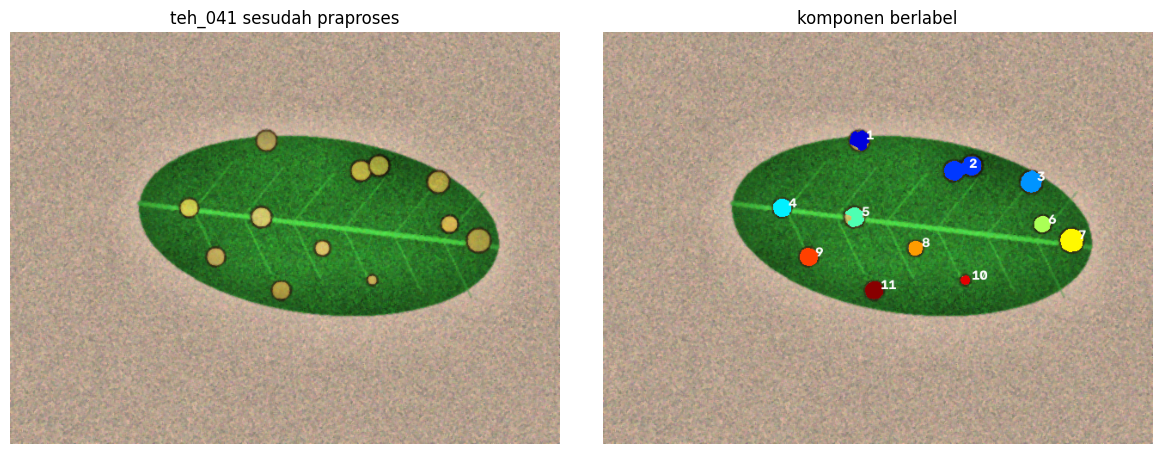

In [20]:
MM_PER_PX = 0.4375  # dari lembar hitung P2: Z = 200 mm, lebar kerja 640 px


def ukur_komponen(m, konek=8):
    n, lbl, st, cen = cv2.connectedComponentsWithStats(
        (m > 0).astype(np.uint8),
        connectivity=konek
    )

    baris = []

    for i in range(1, n):
        kontur, _ = cv2.findContours(
            (lbl == i).astype(np.uint8),
            cv2.RETR_EXTERNAL,
            cv2.CHAIN_APPROX_NONE
        )

        A = int(st[i, cv2.CC_STAT_AREA])

        keliling = cv2.arcLength(kontur[0], True)

        kebulatan = (
            0.0 if keliling == 0
            else 4 * np.pi * A / keliling ** 2
        )

        w, h = cv2.minAreaRect(kontur[0])[1]

        rasio = max(w, h) / max(min(w, h), 1)

        baris.append([
            i,
            A,
            round(A * MM_PER_PX ** 2, 2),
            round(keliling, 1),
            round(kebulatan, 2),
            round(rasio, 2),
            int(cen[i][0]),
            int(cen[i][1])
        ])

    kolom = [
        "label",
        "luas_px",
        "luas_mm2",
        "keliling_px",
        "kebulatan",
        "rasio_aspek",
        "cx",
        "cy"
    ]

    return pd.DataFrame(baris, columns=kolom), lbl


img, md, mb = muat("teh_041.png")

pra_ = praproses(img, PARAM)

m_daun = mask_daun_awal(pra_)

bersih = cv2.morphologyEx(
    cv2.morphologyEx(
        bercak_awal(pra_, m_daun),
        cv2.MORPH_OPEN,
        SE(5)
    ),
    cv2.MORPH_CLOSE,
    SE(5)
)


for konek in [4, 8]:
    print(
        f"konektivitas {konek}: "
        f"{jumlah_komponen(bersih, konek)} komponen"
    )


tabel_kom, lbl = ukur_komponen(bersih)

print(tabel_kom)


warna = cv2.applyColorMap(
    (lbl * (255 // max(lbl.max(), 1))).astype(np.uint8),
    cv2.COLORMAP_JET
)

warna[lbl == 0] = pra_[lbl == 0]


for _, r in tabel_kom.iterrows():
    cv2.putText(
        warna,
        str(int(r.label)),
        (int(r.cx) + 8, int(r.cy)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (255, 255, 255),
        2
    )


tampil(
    [pra_, warna],
    ["teh_041 sesudah praproses", "komponen berlabel"],
    ukuran=(12, 4.5)
)

##**Kode 4.2 Penyaringan komponen berdasarkan ukuran dan bentuk**

In [21]:
def saring(m, luas_min=20, bulat_min=0.5, rasio_maks=1.8):
    tabel_k, lbl = ukur_komponen(m)

    lolos = tabel_k[
        (tabel_k.luas_px >= luas_min) &
        (tabel_k.kebulatan >= bulat_min) &
        (tabel_k.rasio_aspek <= rasio_maks)
    ]

    return (
        np.isin(lbl, lolos.label.values) * 255
    ).astype(np.uint8), lolos


aturan = {
    "tanpa saring": (0, 0, 99),
    "luas >= 20": (20, 0, 99),
    "luas + kebulatan": (20, 0.5, 99),
    "luas + kebulatan + rasio": (20, 0.5, 1.8)
}


baris = []

for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)

    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)

    bersih = cv2.morphologyEx(
        cv2.morphologyEx(
            bercak_awal(pra_, m_daun),
            cv2.MORPH_OPEN,
            SE(5)
        ),
        cv2.MORPH_CLOSE,
        SE(5)
    )

    for nm, (a, b, r) in aturan.items():
        f, _ = saring(bersih, a, b, r)

        baris.append([
            d.kelas,
            nm,
            jumlah_komponen(f),
            jumlah_komponen(mb)
        ])


uji = pd.DataFrame(
    baris,
    columns=["kelas", "aturan", "jumlah", "acuan"]
)

uji["galat"] = (uji.jumlah - uji.acuan).abs()


print(
    uji.pivot_table(
        index="aturan",
        columns="kelas",
        values="galat"
    ).round(2)
)


print("Daun sehat yang masih memiliki bercak palsu:")

print(
    uji[uji.kelas == "sehat"]
    .assign(palsu=lambda t: t.jumlah > 0)
    .groupby("aturan")
    .palsu.sum()
)

kelas                     berat  ringan  sehat
aturan                                        
luas + kebulatan           1.30    1.20   1.30
luas + kebulatan + rasio   1.05    0.70   0.55
luas >= 20                 2.00    1.90   2.10
tanpa saring               2.80    2.95   2.95
Daun sehat yang masih memiliki bercak palsu:
aturan
luas + kebulatan             9
luas + kebulatan + rasio     7
luas >= 20                  10
tanpa saring                10
Name: palsu, dtype: int64


Jumlah komponen berdasarkan status:
status
benar    184
palsu    173
Name: count, dtype: int64


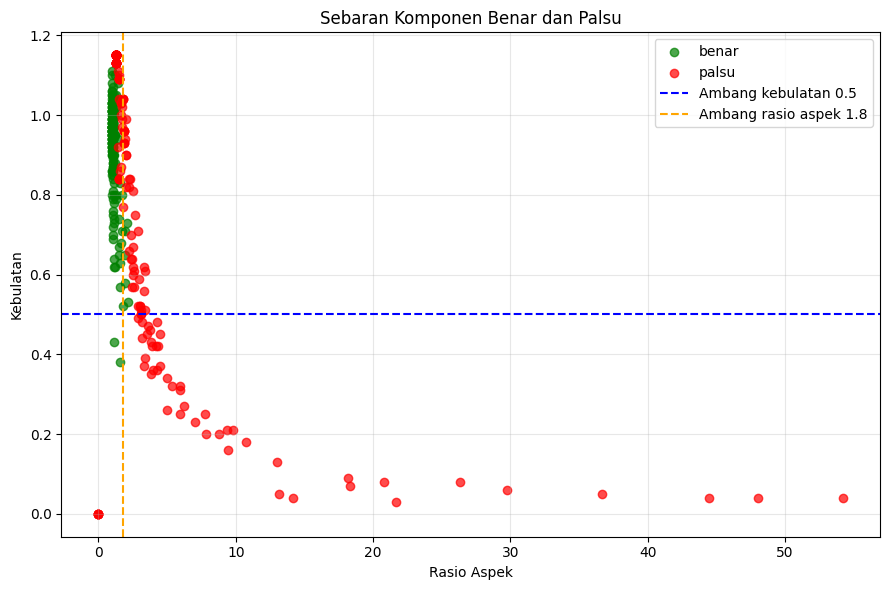


Ringkasan luas komponen:
        count    mean     std   min     25%    50%     75%     max
status                                                            
benar   184.0  353.74  270.83  17.0  141.75  306.0  493.25  1723.0
palsu   173.0  123.27  330.22   1.0   17.00   31.0   60.00  1957.0


In [22]:

baris_komponen = []

for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)

    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)

    bersih = cv2.morphologyEx(
        cv2.morphologyEx(
            bercak_awal(pra_, m_daun),
            cv2.MORPH_OPEN,
            SE(5)
        ),
        cv2.MORPH_CLOSE,
        SE(5)
    )

    tabel_k, lbl = ukur_komponen(bersih)

    acuan = mb > 0

    for _, r in tabel_k.iterrows():
        komponen = lbl == int(r.label)

        luas = np.count_nonzero(komponen)
        irisan = np.count_nonzero(komponen & acuan)

        proporsi = irisan / luas if luas > 0 else 0

        status = "benar" if proporsi > 0.5 else "palsu"

        baris_komponen.append([
            d.nama_file,
            d.kelas,
            int(r.label),
            int(r.luas_px),
            r.kebulatan,
            r.rasio_aspek,
            round(proporsi, 3),
            status
        ])


tabel_komponen = pd.DataFrame(
    baris_komponen,
    columns=[
        "nama_file",
        "kelas",
        "label",
        "luas_px",
        "kebulatan",
        "rasio_aspek",
        "proporsi_acuan",
        "status"
    ]
)

print("Jumlah komponen berdasarkan status:")
print(tabel_komponen["status"].value_counts())


# Diagram sebar kebulatan terhadap rasio aspek
plt.figure(figsize=(9, 6))

for status, warna in [
    ("benar", "green"),
    ("palsu", "red")
]:
    data = tabel_komponen[
        tabel_komponen["status"] == status
    ]

    plt.scatter(
        data["rasio_aspek"],
        data["kebulatan"],
        label=status,
        color=warna,
        alpha=0.7
    )

# Garis ambang yang diuji pada Langkah 4.3
plt.axhline(
    y=0.5,
    color="blue",
    linestyle="--",
    label="Ambang kebulatan 0.5"
)

plt.axvline(
    x=1.8,
    color="orange",
    linestyle="--",
    label="Ambang rasio aspek 1.8"
)

plt.xlabel("Rasio Aspek")
plt.ylabel("Kebulatan")
plt.title("Sebaran Komponen Benar dan Palsu")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

HASIL = "/content/drive/MyDrive/simuteh-2330511058/hasil"
os.makedirs(HASIL, exist_ok=True)

plt.savefig(
    os.path.join(HASIL, "p4_4_sebar_bentuk.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Ringkasan luas komponen benar dan palsu
print("\nRingkasan luas komponen:")
print(
    tabel_komponen.groupby("status")["luas_px"]
    .describe()
    .round(2)
)


In [23]:
# Luas bercak hasil deteksi
luas_hasil = np.count_nonzero(bersih)

# Luas bercak pada mask acuan
luas_acuan = np.count_nonzero(mb > 0)

# Konversi ke mm2
luas_hasil_mm2 = luas_hasil * MM_PER_PX**2
luas_acuan_mm2 = luas_acuan * MM_PER_PX**2

# Persentase selisih
selisih = abs(luas_hasil - luas_acuan) / luas_acuan * 100

print("Luas hasil deteksi:", luas_hasil, "px")
print("Luas mask acuan:", luas_acuan, "px")
print("Luas hasil deteksi:", round(luas_hasil_mm2, 2), "mm2")
print("Luas mask acuan:", round(luas_acuan_mm2, 2), "mm2")
print("Persentase selisih:", round(selisih, 2), "%")

Luas hasil deteksi: 2343 px
Luas mask acuan: 2759 px
Luas hasil deteksi: 448.46 mm2
Luas mask acuan: 528.09 mm2
Persentase selisih: 15.08 %
